In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("../data/result_with_vac.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44608 entries, 0 to 44607
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   title   44608 non-null  object 
 1   x       44608 non-null  float64
 2   y       44608 non-null  float64
 3   B       44608 non-null  float64
 4   dB_dx   44608 non-null  float64
 5   dB_dy   44608 non-null  float64
 6   Jc      44608 non-null  float64
 7   Jx      44608 non-null  float64
 8   Jy      44608 non-null  float64
 9   Ic      19571 non-null  float64
 10  Rn      25787 non-null  float64
 11  n       25787 non-null  float64
dtypes: float64(11), object(1)
memory usage: 4.1+ MB


In [5]:
df

,title,x,y,B,dB_dx,dB_dy,Jc,Jx,Jy,Ic,Rn,n
0,1,-0.01,0.00,-0.000325,-0.12875,-0.0760,1.090335e+08,7.915898e+07,7.498113e+07,NaN,NaN,NaN
1,1,0.79,0.00,-0.000401,-0.22875,-0.0965,9.263875e+07,8.640185e+06,9.223495e+07,NaN,NaN,NaN
2,1,1.59,0.00,-0.000518,-0.36750,-0.1235,4.150431e+07,3.640487e+07,1.993222e+07,NaN,NaN,NaN
3,1,2.39,0.00,-0.000648,-0.49875,-0.1220,4.602157e+08,-4.334496e+08,-1.546606e+08,NaN,NaN,NaN
4,1,3.19,0.00,-0.000762,-0.70125,-0.0860,1.537920e+09,-1.537311e+09,-4.328145e+07,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
44603,9,4.90,109.91,-0.000086,0.03875,0.0025,4.373178e+08,4.358905e+08,3.530410e+07,NaN,NaN,NaN
44604,9,5.70,109.91,-0.000080,0.03125,-0.0005,5.755951e+08,5.747868e+08,3.049295e+07,NaN,NaN,NaN
44605,9,6.50,109.91,-0.000087,0.02000,0.0000,4.489166e+08,4.392080e+08,9.285727e+07,NaN,NaN,NaN
44606,9,7.30,109.91,-0.000080,0.02375,0.0020,4.770703e+08,4.686526e+08,8.922386e+07,NaN,NaN,NaN


In [3]:
df.describe(include='all')

,title,x,y,B,dB_dx,dB_dy,Jc,Jx,Jy,Ic,Rn,n
count,44608,44608.00000,44608.000000,44608.000000,44608.000000,44608.000000,4.460800e+04,4.460800e+04,4.460800e+04,19571.000000,2.578700e+04,25787.000000
unique,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1661,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,4.55082,65.004131,0.000994,0.004992,0.020861,3.306073e+09,5.702838e+06,-8.273462e+07,130.071420,1.594162e-08,0.572158
std,NaN,3.03140,43.491752,0.005102,0.844270,3.490399,4.210129e+09,1.101466e+09,5.237885e+09,66.981945,1.367623e-08,0.911122
min,NaN,-1.44000,-20.010000,-0.007763,-12.134375,-11.983000,1.391623e+06,-2.192591e+10,-3.447863e+10,23.054000,-1.477728e-10,0.035860
25%,NaN,1.76000,30.000000,-0.002031,-0.053750,-0.839000,2.798265e+08,-7.462225e+07,-1.155763e+09,42.978000,3.463503e-10,0.055079
50%,NaN,4.73000,61.980000,-0.000668,0.000625,0.026250,1.139670e+09,2.913048e+06,-4.780780e+07,173.343300,1.092705e-08,0.158940
75%,NaN,7.17000,92.990000,0.001280,0.057500,0.870000,5.421462e+09,8.435189e+07,9.368305e+08,183.182300,2.952706e-08,0.448222


In [6]:
df.isna().sum()

title        0
x            0
y            0
B            0
dB_dx        0
dB_dy        0
Jc           0
Jx           0
Jy           0
Ic       25037
Rn       18821
n        18821
dtype: int64

In [7]:
df = df.drop('title', axis = 1)

## Distribution of features and target variable J_c

For greater clarity, we will use a logarithmic scale for the critical current density, since the values ​​vary from zero to 1.2×10¹⁰ A/m²

In [8]:
df['log_Jc'] = np.log10(df['Jc'].replace(0, np.nan))

Text(0.5, 1.0, 'log Jc histogram')

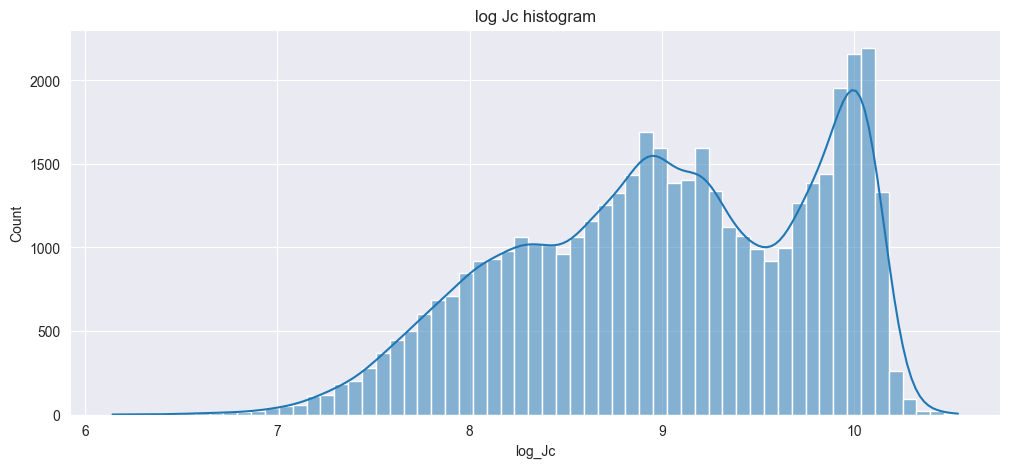

In [9]:
plt.figure(figsize=(12, 5))
sns.histplot(df['log_Jc'].dropna(), kde=True)
plt.title("log Jc histogram")

Text(0.5, 1.0, 'Histogram of B, T')

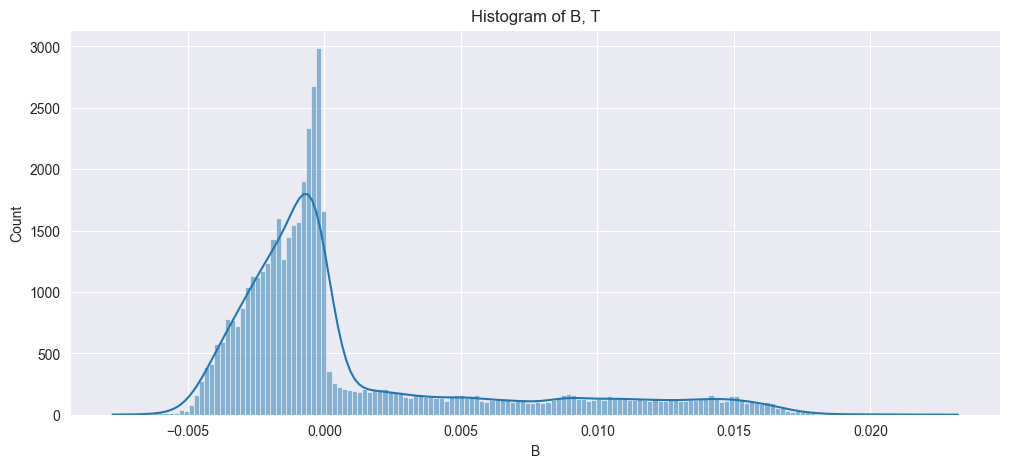

In [10]:
plt.figure(figsize=(12, 5))
sns.histplot(df['B'].dropna(), kde=True)
plt.title("Histogram of B, T" )

Text(0.5, 1.0, 'Histogram of dB_dx')

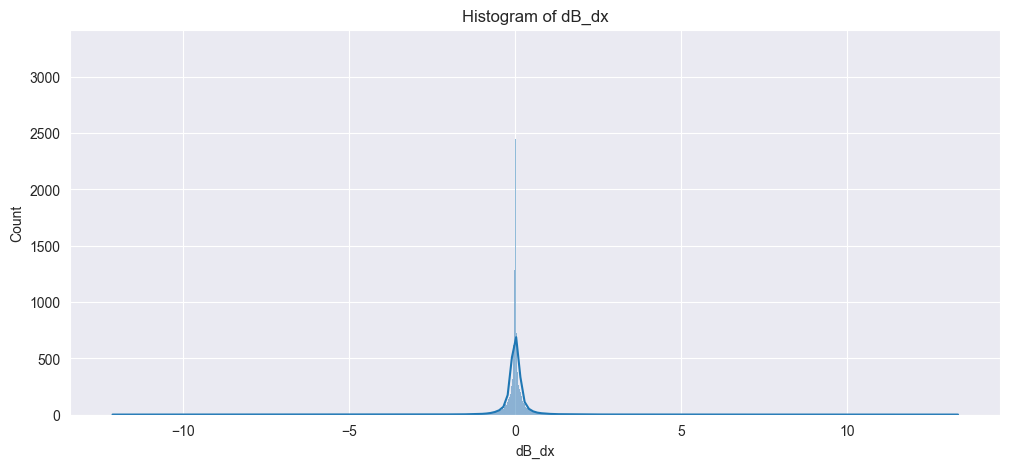

In [11]:
plt.figure(figsize=(12, 5))
sns.histplot(df['dB_dx'].dropna(), kde=True)
plt.title("Histogram of dB_dx" )

Text(0.5, 1.0, 'Histogram of dB_dy')

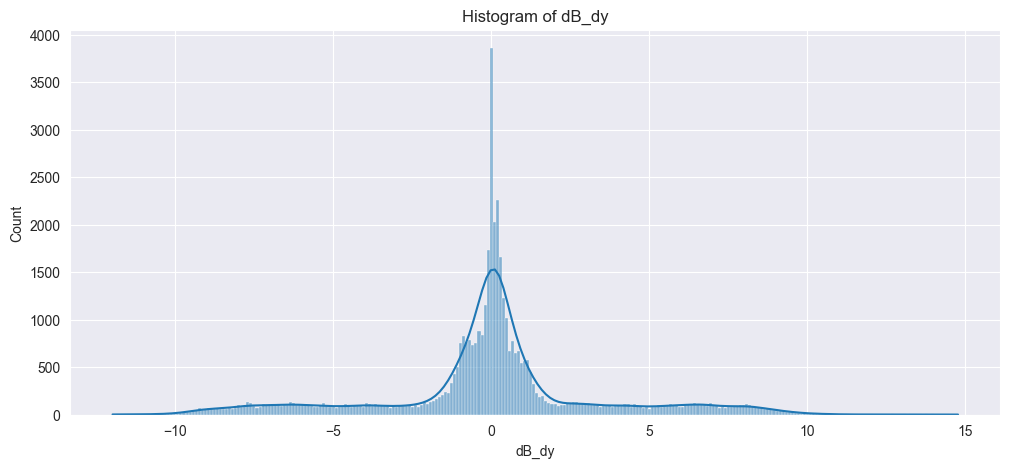

In [12]:
plt.figure(figsize=(12, 5))
sns.histplot(df['dB_dy'].dropna(), kde=True)
plt.title("Histogram of dB_dy" )

Text(0.5, 1.0, 'Histogram of Ic')

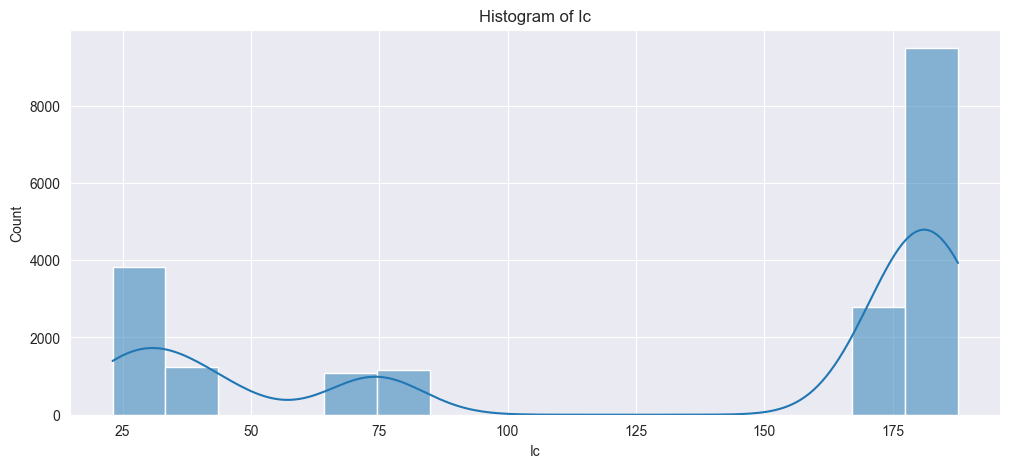

In [13]:
plt.figure(figsize=(12, 5))
sns.histplot(df['Ic'].dropna(), kde=True)
plt.title("Histogram of Ic" )

Text(0.5, 1.0, 'Histogram of Rn')

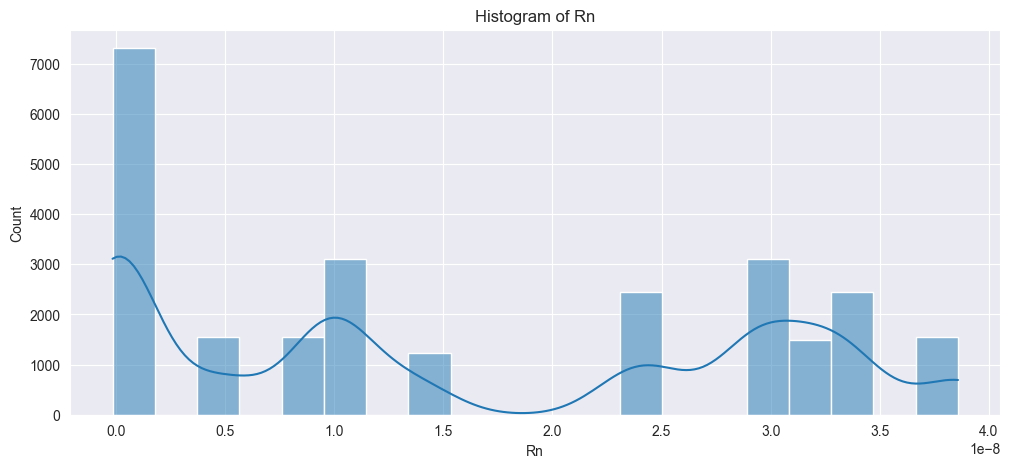

In [14]:
plt.figure(figsize=(12, 5))
sns.histplot(df['Rn'].dropna(), kde=True)
plt.title("Histogram of Rn" )

Text(0.5, 1.0, 'Histogram of n')

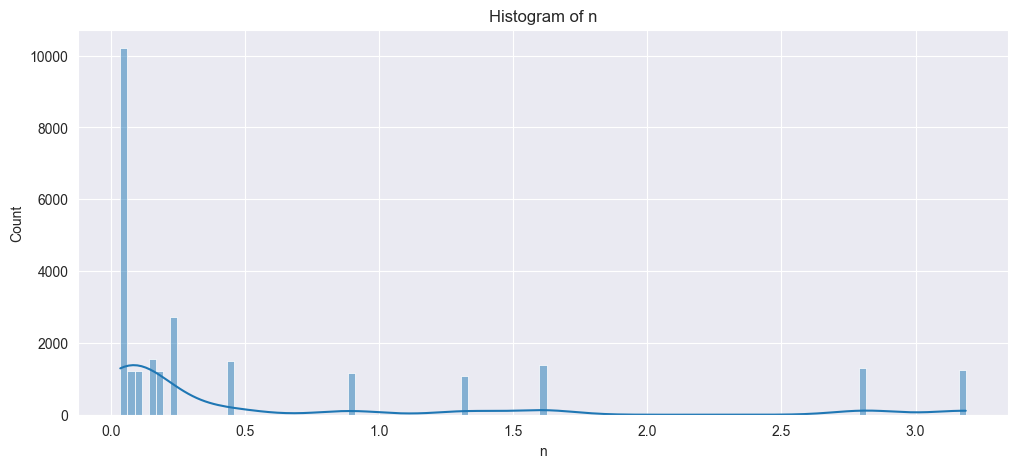

In [15]:
plt.figure(figsize=(12, 5))
sns.histplot(df['n'].dropna(), kde=True)
plt.title("Histogram of n" )

## Correlation plot

           x     y     B  dB_dx  dB_dy    Jc    Jx    Jy    Ic    Rn     n  \
x       1.00 -0.04 -0.04  -0.00  -0.15 -0.08 -0.00  0.16  0.06  0.03 -0.07   
y      -0.04  1.00 -0.04  -0.04  -0.01 -0.12 -0.09  0.01 -0.39 -0.32  0.01   
B      -0.04 -0.04  1.00  -0.00  -0.00  0.50 -0.00  0.01  0.12  0.09 -0.07   
dB_dx  -0.00 -0.04 -0.00   1.00  -0.07 -0.00  0.87  0.07  0.01  0.01 -0.00   
dB_dy  -0.15 -0.01 -0.00  -0.07   1.00  0.00 -0.05 -0.98  0.00  0.00 -0.00   
Jc     -0.08 -0.12  0.50  -0.00   0.00  1.00 -0.00 -0.01  0.38  0.25 -0.25   
Jx     -0.00 -0.09 -0.00   0.87  -0.05 -0.00  1.00  0.05  0.01  0.01 -0.00   
Jy      0.16  0.01  0.01   0.07  -0.98 -0.01  0.05  1.00 -0.01 -0.01  0.01   
Ic      0.06 -0.39  0.12   0.01   0.00  0.38  0.01 -0.01  1.00  0.90 -0.81   
Rn      0.03 -0.32  0.09   0.01   0.00  0.25  0.01 -0.01  0.90  1.00 -0.55   
n      -0.07  0.01 -0.07  -0.00  -0.00 -0.25 -0.00  0.01 -0.81 -0.55  1.00   
log_Jc -0.07 -0.17  0.41   0.00  -0.01  0.82  0.00 -0.01  0.48  

Text(0.5, 1.0, 'Correlation plot')

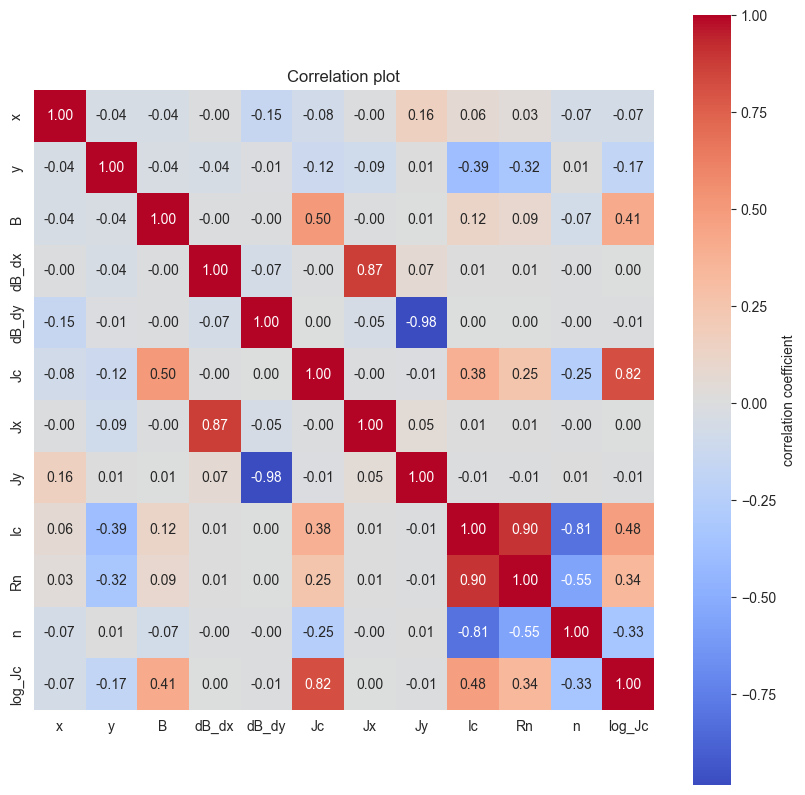

In [16]:
corr = df.corr()

print(corr.round(2))

plt.figure(figsize = (10,10))
sns.heatmap(corr, annot = True, cmap = 'coolwarm',
            cbar_kws = {'label' : 'correlation coefficient'},
            square = True, fmt ='.2f')
plt.title('Correlation plot')

## Pairplots

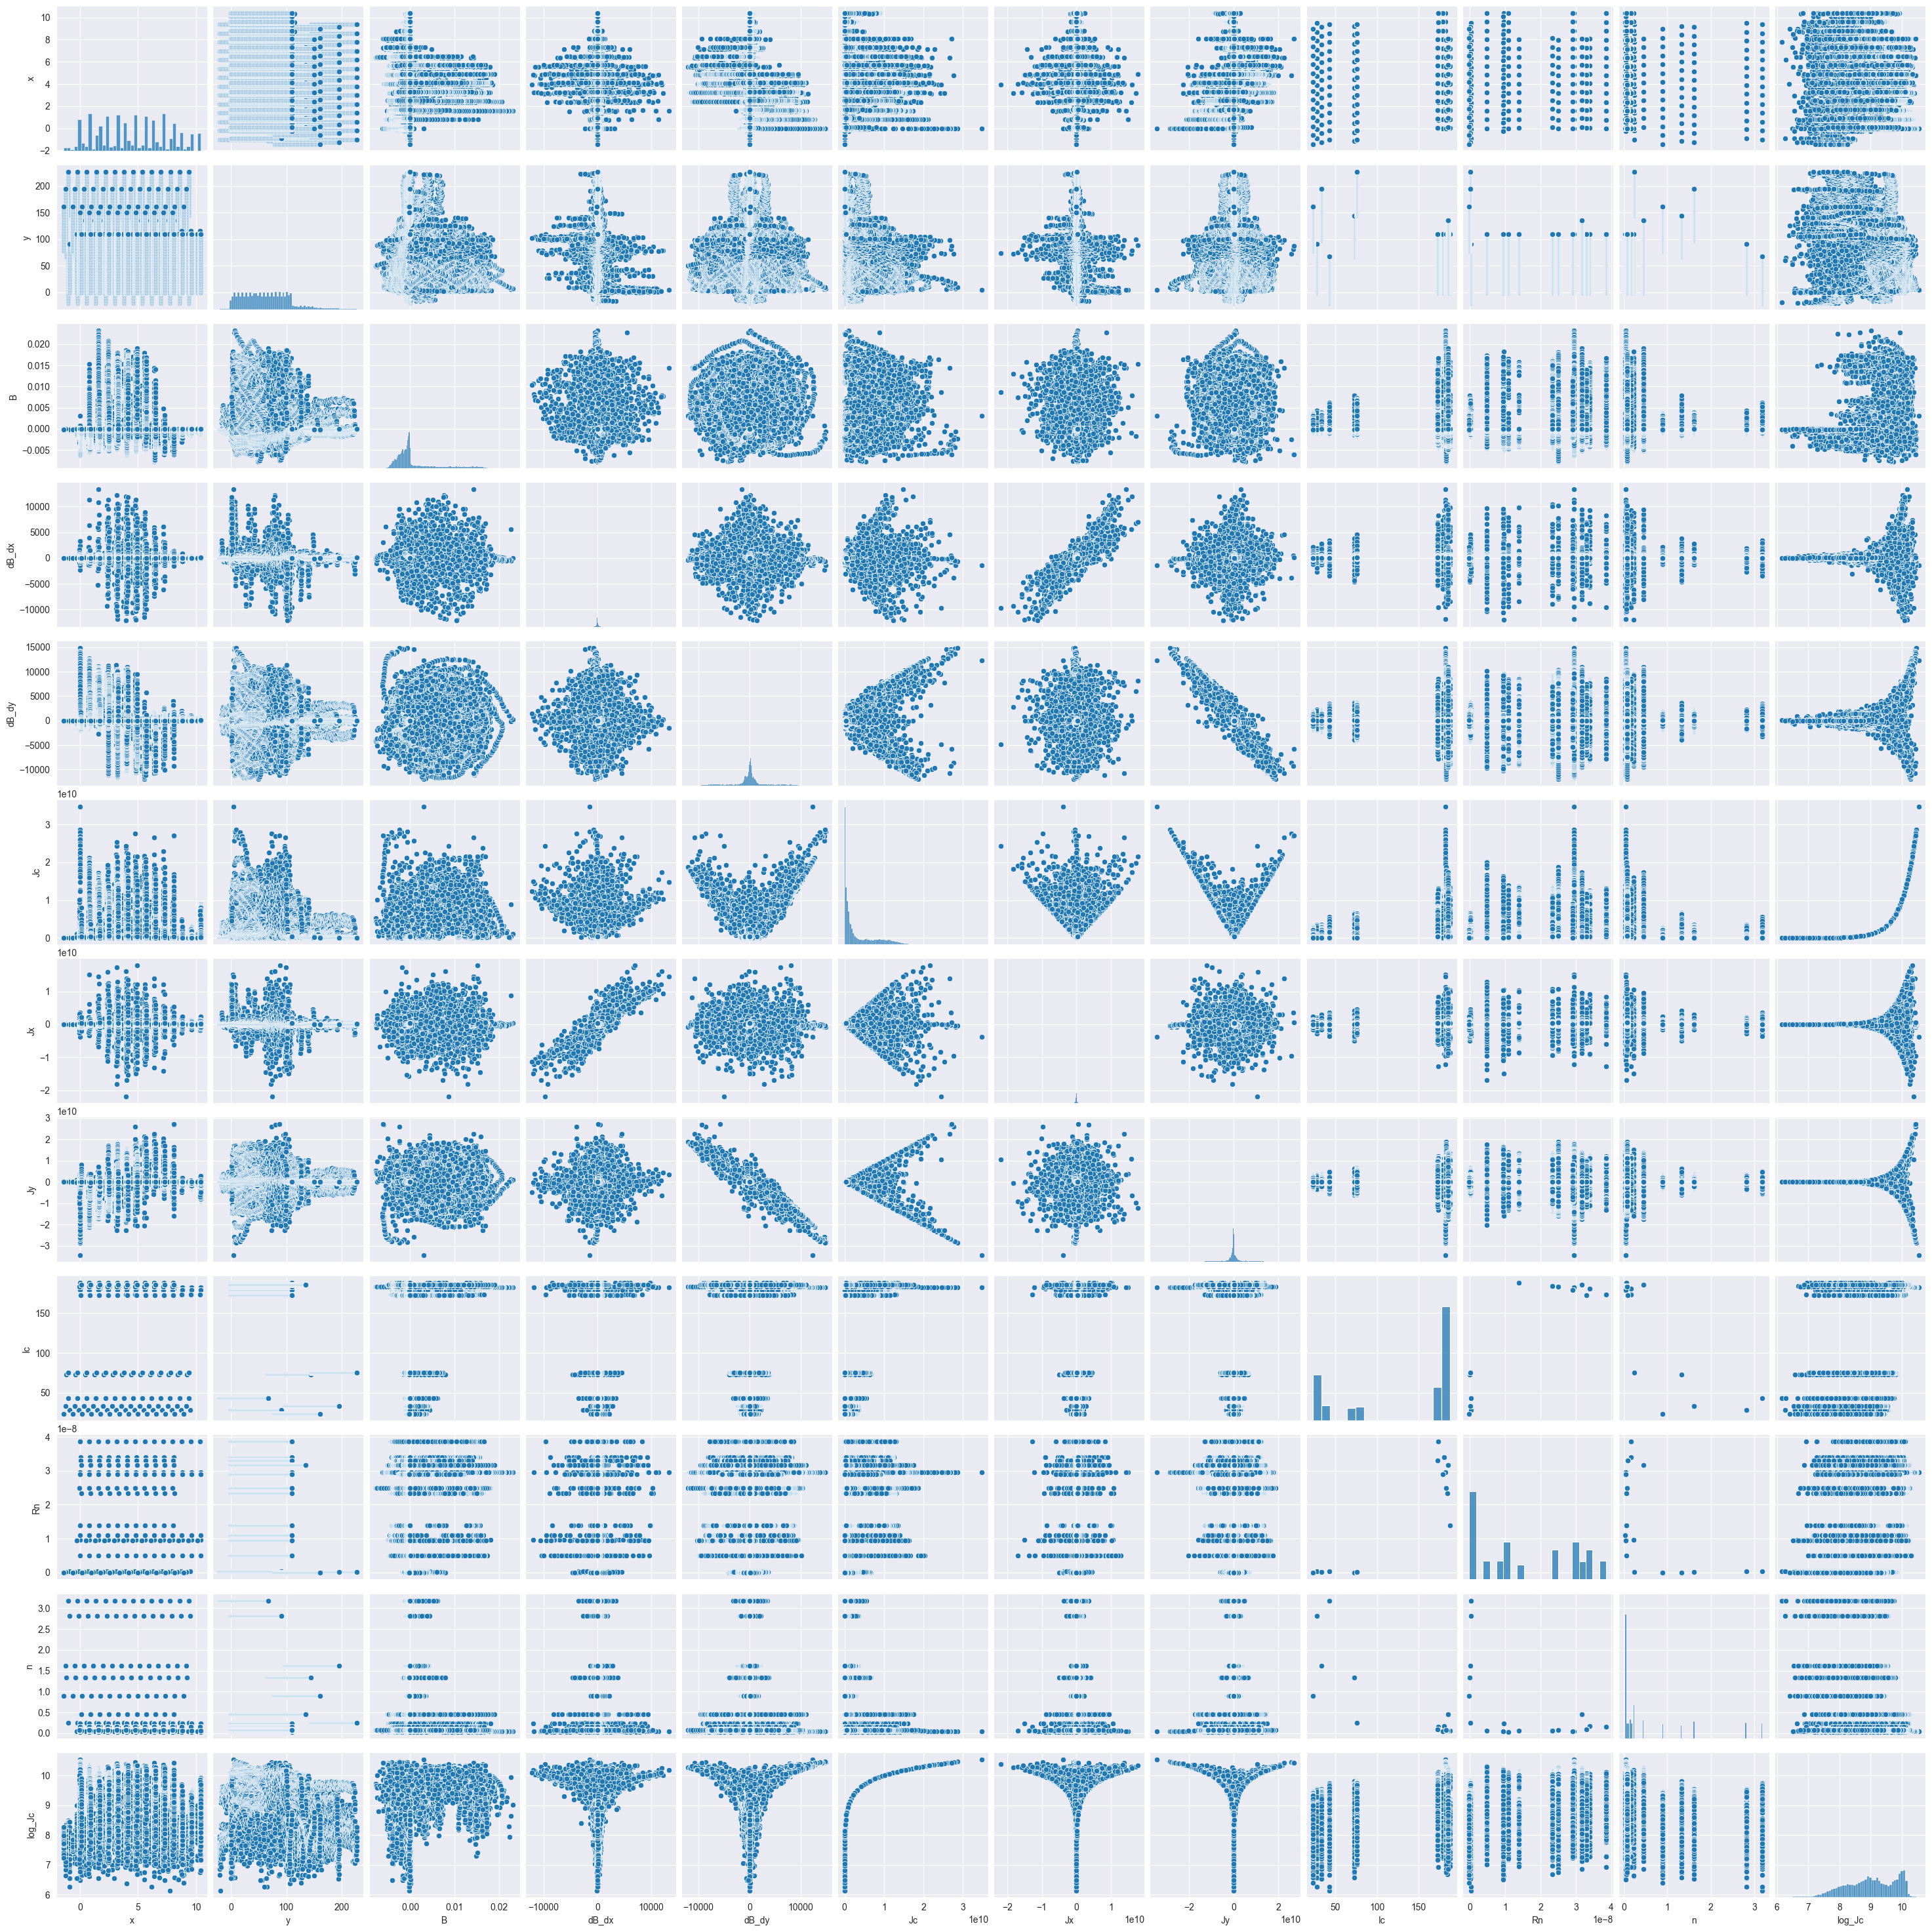

In [16]:
sns.pairplot(df)

## Sample heatmap (B, J_c)

In [23]:
df = pd.read_csv("../data/result_with_vac.csv")
sample = df[df['title'] == '2']
sample

,title,x,y,B,dB_dx,dB_dy,Jc,Jx,Jy,Ic,Rn,n
21956,2,0.04,0.05,-0.000610,-257.50,-142.0,2.726966e+08,2.651206e+08,6.383195e+07,172.7515,3.298998e-08,0.091811
21957,2,0.84,0.05,-0.000752,-305.00,-144.0,3.128957e+08,3.073234e+08,5.878806e+07,172.7515,3.298998e-08,0.091811
21958,2,1.64,0.05,-0.000898,-101.25,-139.0,3.604888e+08,3.591145e+08,3.144747e+07,172.7515,3.298998e-08,0.091811
21959,2,2.44,0.05,-0.001030,332.50,-107.0,4.009595e+08,3.996202e+08,3.274430e+07,172.7515,3.298998e-08,0.091811
21960,2,3.24,0.05,-0.001112,772.50,-41.5,5.450952e+08,5.416984e+08,6.075821e+07,172.7515,3.298998e-08,0.091811
...,...,...,...,...,...,...,...,...,...,...,...,...
23172,2,4.84,110.05,-0.000138,47.50,2.0,4.658794e+08,4.625386e+08,5.569290e+07,172.7515,3.298998e-08,0.091811
23173,2,5.64,110.05,-0.000127,73.75,3.5,5.522539e+08,5.478465e+08,6.963233e+07,172.7515,3.298998e-08,0.091811
23174,2,6.44,110.05,-0.000131,53.75,-2.5,4.171891e+08,4.025689e+08,1.094760e+08,172.7515,3.298998e-08,0.091811
23175,2,7.24,110.05,-0.000132,47.50,5.5,3.631225e+08,3.567806e+08,6.756904e+07,172.7515,3.298998e-08,0.091811


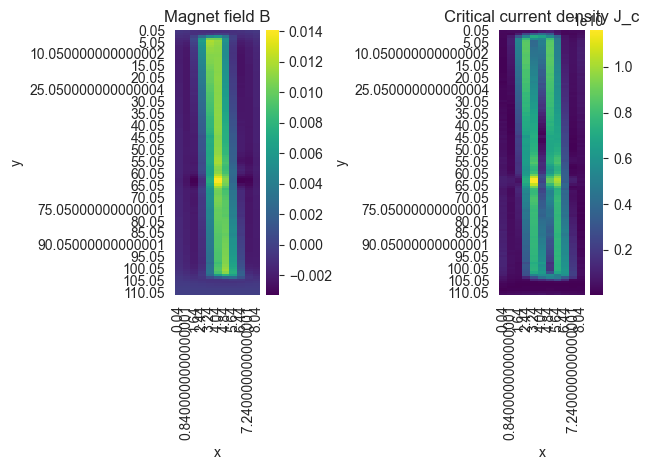

In [34]:
plt.subplot(1, 2, 1)
pivot_B = sample.pivot_table(index='y', columns='x', values='B')
sns.heatmap(pivot_B, cmap='viridis')
plt.title(f"Magnet field B")

plt.subplot(1, 2, 2)
pivot_Jc = sample.pivot_table(index='y', columns='x', values='Jc')
sns.heatmap(pivot_Jc, cmap='viridis')
plt.title(f"Critical current density J_c")

plt.tight_layout()
plt.show()

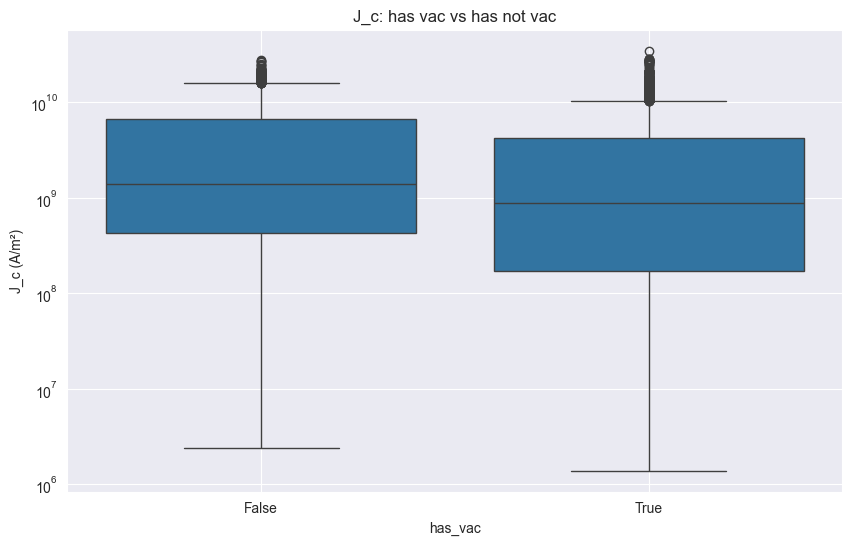

In [36]:
df['has_vac'] = df['Ic'].notna()
plt.figure(figsize=(10, 6))
sns.boxplot(x='has_vac', y='Jc', data=df)
plt.title("J_c: has vac vs has not vac")
plt.ylabel("J_c (A/m²)")
plt.yscale("log")
plt.grid(True)
plt.show()